[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch19_Lab08_RNN_Number_Prediction.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 19: Recurrent Networks** (Part IV: Meaning and Memory). Also used in Chapter 9.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=19](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=19)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab 08 — Recurrent Neural Network (RNN): Next-Number Prediction

**Goal:** understand how an RNN reads a *sequence* one step at a time, then build, train and test a Keras `SimpleRNN` that predicts the **next number** in a series.

| Part | What you do |
|---|---|
| 1 | See the RNN picture (folded and unrolled) |
| 2 | Theory: equations, what each does, BPTT, pros and cons |
| 3 | Build the dataset (arithmetic series) |
| 4 | Build + train the Keras model |
| 5 | Verify the equations by hand against the trained weights |
| 6 | Predict on your own series, and multi-step forecast |
| 7 | Trials to try |

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Honest test set.** The original drew 3000 random series from only 510 distinct ones, so 592 of the 600 test series were also in training. Now the 510 distinct series are split into train / validation / test with no overlap, and the notebook prints the overlap (0) to prove it.
> * **Early stopping now watches a validation set**, not the test set, so the test score is not used to pick the model. Epochs raised to 600 (patience 30) because there are fewer, distinct training series.
> * `W_hh` printout and Exercise 3: Keras stores the recurrent matrix as *from × to* (it computes `h @ W_hh`), so unit 1's influence is **row 0**, not column 0.
> * Trials table renumbered in order (13 before 14); trial 11 rewritten for the new dataset.

## 1. Picture of an RNN
Left: the **folded** view (one cell feeding itself). Right: the same cell **unrolled** over 5 time steps. *Same weights are reused at every step.*

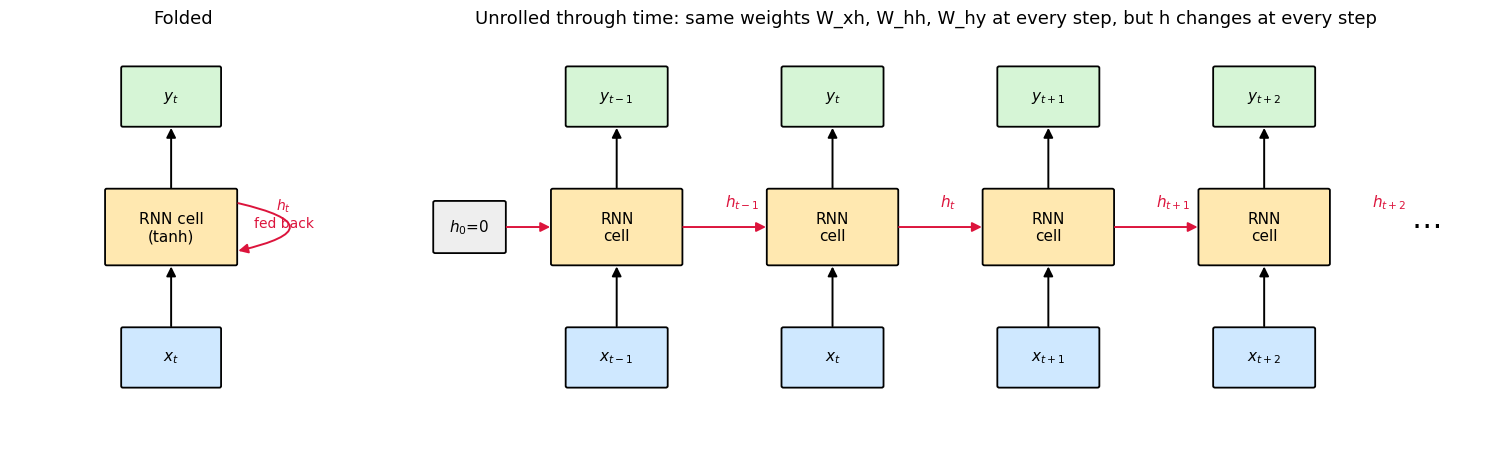

In [1]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02", fc=color, ec="k", lw=1.3))
    ax.text(x, y, text, ha="center", va="center", fontsize=11)

def arr(ax, p, q, rad=0.0, color="k"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=14, lw=1.4, color=color,
                                 connectionstyle=f"arc3,rad={rad}"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 3.2]})
# Folded
a1.set_xlim(0, 4.3); a1.set_ylim(0, 5); a1.axis("off"); a1.set_title("Folded", fontsize=13)
box(a1, 2, 1, 1.2, .7, "$x_t$", "#cfe8ff"); box(a1, 2, 2.6, 1.6, .9, "RNN cell\n(tanh)", "#ffe8b0"); box(a1, 2, 4.2, 1.2, .7, "$y_t$", "#d6f5d6")
arr(a1, (2, 1.35), (2, 2.15)); arr(a1, (2, 3.05), (2, 3.85))
arr(a1, (2.8, 2.9), (2.8, 2.3), rad=-2.2, color="crimson"); a1.text(3.4, 2.6, "$h_t$\nfed back", color="crimson", fontsize=10, ha="center")
# Unrolled
a2.set_xlim(-1.0, 10.3); a2.set_ylim(0, 5); a2.axis("off"); a2.set_title("Unrolled through time: same weights W_xh, W_hh, W_hy at every step, but h changes at every step", fontsize=13)
xs = [1.5, 3.7, 5.9, 8.1]; labels = ["t-1", "t", "t+1", "t+2"]
box(a2, 0.0, 2.6, .7, .6, "$h_0$=0", "#eeeeee")
prev = (0.35, 2.6)
for x, l in zip(xs, labels):
    box(a2, x, 1, 1.0, .7, f"$x_{{{l}}}$", "#cfe8ff"); box(a2, x, 2.6, 1.3, .9, "RNN\ncell", "#ffe8b0"); box(a2, x, 4.2, 1.0, .7, f"$y_{{{l}}}$", "#d6f5d6")
    arr(a2, (x, 1.35), (x, 2.15)); arr(a2, (x, 3.05), (x, 3.85)); arr(a2, prev, (x-.65, 2.6), color="crimson")
    prev = (x+.65, 2.6)
    a2.text(x+1.1, 2.85, f"$h_{{{l}}}$", color="crimson", fontsize=11)
a2.text(9.6, 2.6, "…", fontsize=22)
plt.tight_layout(); plt.show()

## 2. RNN theory

### 2.1 Why an RNN?
A DNN or CNN sees a **fixed-size input with no memory**. A sequence (numbers, words, audio, sensor values) has **order**: `2,4,6,8` → `10` is predictable only if the model remembers what came before. An RNN carries a **hidden state** $h_t$, a running summary of everything seen so far, from one step to the next.

### 2.2 The equations to remember

| # | Equation | What it does |
|---|---|---|
| 1 | $a_t = W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h$ | **Mixes** the new input with the memory of the past. $W_{xh}$ decides how to read the input, $W_{hh}$ decides how much of the old memory to keep and how to transform it. |
| 2 | $h_t = \tanh(a_t)$ | **Non-linearity**: squashes to $[-1,1]$, keeps the state bounded, lets the network learn non-linear patterns. $h_t$ is the new memory. |
| 3 | $\hat y_t = W_{hy}\,h_t + b_y$ | **Read-out**: turns memory into a prediction. Linear for regression (our case); softmax for classification. |
| 4 | $h_0 = 0$ | **Initial memory**: blank before the first element. |
| 5 | $L = \frac{1}{T}\sum_t (y_t-\hat y_t)^2$ | **Loss** (MSE for numbers). In our lab only the last step $T$ is compared with the target. |
| 6 | $\dfrac{\partial L}{\partial W_{hh}}=\sum_{t}\dfrac{\partial L}{\partial h_T}\Big(\prod_{k=t+1}^{T}\mathrm{diag}(1-h_k^2)\,W_{hh}^{\top}\Big)\dfrac{\partial h_t}{\partial W_{hh}}$ | **Back-propagation Through Time (BPTT)**: unroll, then apply the chain rule backwards. The *product* term is the source of vanishing/exploding gradients. |
| 7 | $\theta \leftarrow \theta-\eta\,\nabla_\theta L$ (Adam in practice) | **Weight update**. |

**Key idea:** the *same* $W_{xh},W_{hh},W_{hy}$ are shared across all time steps (weight sharing, like a CNN kernel shared across space).

**Parameter count** for `SimpleRNN(units=n)` with input size $d$ and a `Dense(1)` head:
$$n(d+n+1)\;+\;(n+1)$$
Example: $n=8,d=1$ → $8\cdot10 + 9 = 89$.

### 2.2b How to read the symbols (reference)

| Symbol | Name | Meaning |
|---|---|---|
| $\partial$ | partial derivative | Rate of change with respect to **one** variable, others held fixed. $\frac{\partial L}{\partial W_{hh}}$ = "how much the loss changes per small change in $W_{hh}$". Example: $L=3w^2 \Rightarrow \frac{\partial L}{\partial w}=6w$. |
| $\nabla_\theta L$ | **gradient** ("nabla theta L", "del theta L") | The *list* of all partial derivatives $[\partial L/\partial\theta_1,\dots,\partial L/\partial\theta_n]$, one per parameter (89 numbers for our lab model). It points **uphill**. |
| $\sum_{t=1}^{T}$ | sigma, sum | Add the terms for $t=1,\dots,T$. |
| $\prod_{k=t+1}^{T}$ | pi, product | Multiply the terms for $k=t+1,\dots,T$. |
| $W^{\top}$ | transpose | Flip rows and columns. |
| $\mathrm{diag}(v)$ | diagonal matrix | Put vector $v$ on the diagonal, zeros elsewhere. |
| $\theta$ | theta | All trainable parameters ($W_{xh},W_{hh},W_{hy},b_h,b_y$). |
| $\eta$ | eta | Learning rate (step size). |
| $\leftarrow$ | assign | "Overwrite with". Not an equality. |

**Reading equation 6 (BPTT), right to left**

$$\frac{\partial L}{\partial W_{hh}}=\sum_{t=1}^{T}\frac{\partial L}{\partial h_T}\Big(\prod_{k=t+1}^{T}\mathrm{diag}(1-h_k^2)\,W_{hh}^{\top}\Big)\frac{\partial h_t}{\partial W_{hh}}$$

* $\frac{\partial h_t}{\partial W_{hh}}$: the **direct** effect of $W_{hh}$ at step $t$ (one cell only).
* $\prod_{k=t+1}^{T}$: carries that effect forward from step $t$ to the last step $T$. Each step contributes one factor $\frac{\partial h_k}{\partial h_{k-1}}=\mathrm{diag}(1-h_k^2)\,W_{hh}^{\top}$. The $W_{hh}^{\top}$ is from the linear part; $1-h_k^2$ is the **tanh derivative** ($\tanh'(a)=1-\tanh^2 a$), diagonal because tanh acts element by element, entries $\le 1$.
* $\frac{\partial L}{\partial h_T}$: how the loss reacts to the final state.
* $\sum_t$: $W_{hh}$ is used at **every** step, so add the contribution from every step.

In words: *(loss sensitivity at the end) × (chain of per-step sensitivities from $t$ to $T$) × (local effect of $W_{hh}$ at $t$), summed over $t$.*

**Why the product matters.** A step far from $T$ has many factors multiplied: $0.5^{20}\approx10^{-6}$ (vanishing), $1.5^{20}\approx3300$ (exploding). Scalar example: $W_{hh}=0.5$, $h\approx0.5$ gives each factor $(1-0.25)\times0.5=0.375$, and after 5 steps $0.375^5\approx0.007$: the input from 5 steps ago contributes under 1% of the signal. Section 5 measures this on the trained model.

**Reading equation 7, weight update: $\theta\leftarrow\theta-\eta\,\nabla_\theta L$**

Move every parameter a small step **against** its gradient (downhill). Example: $\theta=2.0$, gradient $=4$, $\eta=0.01$ gives $\theta=2.0-0.04=1.96$.

**Adam** (what Keras actually uses) keeps two running averages per parameter, with $g_t=\nabla_\theta L$:

$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t\ \text{(smoothed direction)}\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2\ \text{(typical size)}$$
$$\theta\leftarrow\theta-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$

$\hat m,\hat v$ are bias-corrected; defaults $\beta_1=0.9,\ \beta_2=0.999,\ \epsilon=10^{-7}$. The $m$ term smooths noise; dividing by $\sqrt v$ gives **each parameter its own step size**. Adam does **not** cure exploding gradients (use `clipnorm`) or vanishing gradients (use LSTM/GRU). Too large an $\eta$ diverges; too small is slow; $10^{-3}$ is a good default.

### 2.3 Vanishing and exploding gradients (equation 6)
The product $\prod \mathrm{diag}(1-h_k^2)W_{hh}^{\top}$ is repeated once per time step.
* If its norm is $<1$ → gradient **shrinks exponentially** → early steps are not learned (*vanishing*).
* If $>1$ → gradient **blows up** → unstable training (*exploding*; fix with gradient clipping).

This is why **LSTM** and **GRU** were invented: they add *gates* so the memory can pass through time almost unchanged.

LSTM at a glance (for later): forget gate $f_t=\sigma(W_f[h_{t-1},x_t]+b_f)$, input gate $i_t$, candidate $\tilde c_t=\tanh(\cdot)$, cell $c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t$, output gate $o_t$, $h_t=o_t\odot\tanh(c_t)$.

### 2.4 Pros and cons

| Pros | Cons |
|---|---|
| Handles **variable-length** sequences | **Slow**: steps are sequential, cannot be parallelised across time |
| **Few parameters** (weight sharing) | **Vanishing/exploding gradients**; forgets long-range history |
| Has **memory** of order and context | Hard to train on long sequences |
| Natural for time series, text, speech, sensors | Sensitive to input **scaling** |
| Small and cheap to run on edge devices | Generally **outperformed by LSTM/GRU/Transformers** on long dependencies |

### 2.5 Input / output shapes in Keras (most common bug!)
* Input to an RNN layer: **`(batch, timesteps, features)`**. Ours: `(N, 5, 1)`.
* `return_sequences=False` → output only the **last** $h_T$: `(batch, units)`.
* `return_sequences=True` → output **every** $h_t$: `(batch, timesteps, units)` (needed to stack RNN layers).

### 2.6 Units, cell, time steps (do not mix these up)

* **Unit** = one hidden neuron = **one number** of the memory. `SimpleRNN(8)` means 8 units, so the hidden state $h_t$ is a vector of 8 numbers.
* **Cell** = one time step of the **whole layer** (all $n$ units running in parallel). One box in the unrolled diagram is one cell, not one unit.
* **Time steps $T$** = how many times the cell is reused (5 in this lab). Boxes side by side are the **same** layer at different times, with the same weights.

Each unit receives the input **and all $n$ previous state values**:
$$h_t^{(i)}=\tanh\Big(w^{x}_i\,x_t+\sum_{j=1}^{n}W_{hh}^{(ij)}\,h_{t-1}^{(j)}+b_i\Big)$$

**Every arrow is its own weight.** For $n=3$ the recurrent matrix has 9 independent numbers:

| | from $h^{(1)}$ | from $h^{(2)}$ | from $h^{(3)}$ |
|---|---|---|---|
| **to unit 1** | $w_{11}$ | $w_{12}$ | $w_{13}$ |
| **to unit 2** | $w_{21}$ | $w_{22}$ | $w_{23}$ |
| **to unit 3** | $w_{31}$ | $w_{32}$ | $w_{33}$ |

These 9 numbers differ from each other, but are **the same 9 numbers at every time step**. *Weight sharing means "same across time", not "same across arrows".* A large $w_{21}$ means unit 2 relies on unit 1's previous value; a diagonal weight such as $w_{22}$ is how a unit remembers its own past.

**And $h_t$ is NOT shared across time.** Weights are identical at every step; $h_t$ changes at every step because each step gets a new $x_t$ and the previous $h$. If $h$ never changed there would be no memory. Section 5 prints the changing $h$.

| Same at every step | Different at every step |
|---|---|
| $W_{xh},W_{hh},b_h,W_{hy},b_y$ | $x_t,\ h_t,\ \hat y_t$ |

### 2.7 $d$ versus $T$ (Keras input shape `(batch, timesteps, features)`)

* $d$ = **features** = how many numbers describe the input at **one** step.
* $T$ = **timesteps** = how many steps in the sequence.

| Data | $T$ | $d$ | $W_{xh}$ shape |
|---|---|---|---|
| This lab: 5 numbers of a series | 5 | 1 | $1\times n$ |
| Temperature + humidity + wind per hour, last 24 h | 24 | 3 | $3\times n$ |
| Sentence of 10 words, 100-dim embeddings | 10 | 100 | $100\times n$ |

Only $d$ affects the parameter count; $T$ does not.

### 2.8 How to count trainable parameters

**Rule: every arrow is one weight; every unit that receives arrows has one bias.**

| Layer | Parameters | Why |
|---|---|---|
| SimpleRNN($n$), input $d$ | $n(d+n+1)$ | $W_{xh}$: $dn$, $W_{hh}$: $n^2$, $b_h$: $n$ |
| Dense(1) after $n$ units | $n+1$ | $W_{hy}$: $n$, $b_y$: 1 |
| LSTM($n$) | $4\,n(d+n+1)$ | 4 sets: forget, input, candidate, output |
| GRU($n$) | $3\,n(d+n+1)$ | 3 sets |
| Dense(in → out) | in·out + out | |

Worked example, $n=3,d=1$: $3\times5=15$ (RNN) $+\ 4$ (Dense) $=19$. Lab model, $n=8,d=1$: $80+9=89$. Not counted: $T$ (weights reused) and tanh (no parameters). The picture below counts every arrow for $n=3$.

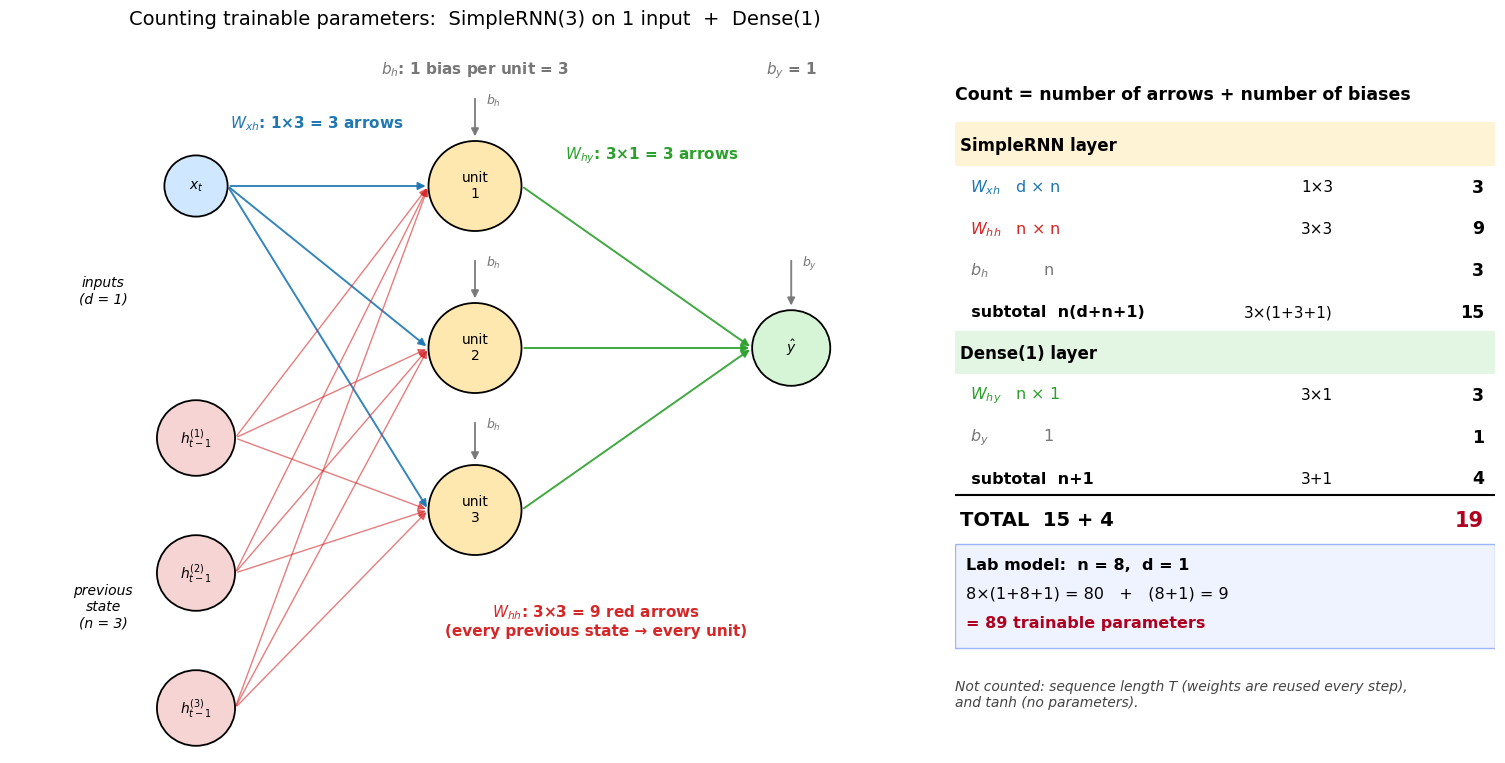

In [2]:
from matplotlib.patches import Circle, FancyArrowPatch
BLUE, RED, GREEN, GRAY = "#1f77b4", "#d62728", "#2ca02c", "#777777"
fig = plt.figure(figsize=(15, 7.2))
ax = fig.add_axes([0.0, 0.0, 0.62, 1]); ax.set_xlim(0, 10); ax.set_ylim(0, 8); ax.axis("off")
def node(x, y, label, fc, r=0.34):
    ax.add_patch(Circle((x, y), r, fc=fc, ec="k", lw=1.3, zorder=3)); ax.text(x, y, label, ha="center", va="center", fontsize=10, zorder=4)
def arrow(p, q, c, lw=1.4, a=0.9):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=11, lw=lw, color=c, alpha=a, zorder=2))
ax.set_title("Counting trainable parameters:  SimpleRNN(3) on 1 input  +  Dense(1)", fontsize=14, pad=6)
ux, uy = 5.0, [6.3, 4.5, 2.7]; hx, hy = 2.0, [3.5, 2.0, 0.5]; xx, xy = 2.0, 6.3; yx, yy = 8.4, 4.5
node(xx, xy, "$x_t$", "#cfe8ff")
for j, y in enumerate(hy): node(hx, y, f"$h_{{t-1}}^{{({j+1})}}$", "#f7d4d4", r=0.42)
for i, y in enumerate(uy): node(ux, y, f"unit\n{i+1}", "#ffe8b0", r=0.5)
node(yx, yy, "$\\hat y$", "#d6f5d6", r=0.42)
for y in uy: arrow((xx+.34, xy), (ux-.5, y), BLUE)
for y0 in hy:
    for y in uy: arrow((hx+.42, y0), (ux-.5, y), RED, lw=1.0, a=.6)
for y in uy: arrow((ux+.5, y), (yx-.42, yy), GREEN)
for y in uy:
    arrow((ux, y+1.0), (ux, y+.52), GRAY); ax.text(ux+.12, y+.9, "$b_h$", fontsize=9, color=GRAY)
arrow((yx, yy+1.0), (yx, yy+.44), GRAY); ax.text(yx+.12, yy+.9, "$b_y$", fontsize=9, color=GRAY)
ax.text(3.3, 6.95, "$W_{xh}$: 1×3 = 3 arrows", color=BLUE, fontsize=11, ha="center", weight="bold")
ax.text(6.3, 1.3, "$W_{hh}$: 3×3 = 9 red arrows\n(every previous state → every unit)", color=RED, fontsize=11, ha="center", weight="bold")
ax.text(6.9, 6.6, "$W_{hy}$: 3×1 = 3 arrows", color=GREEN, fontsize=11, ha="center", weight="bold")
ax.text(5.0, 7.55, "$b_h$: 1 bias per unit = 3", color=GRAY, fontsize=11, ha="center", weight="bold")
ax.text(8.4, 7.55, "$b_y$ = 1", color=GRAY, fontsize=11, ha="center", weight="bold")
ax.text(1.0, 5.0, "inputs\n(d = 1)", ha="center", fontsize=10, style="italic")
ax.text(1.0, 1.4, "previous\nstate\n(n = 3)", ha="center", fontsize=10, style="italic")
t = fig.add_axes([0.63, 0.04, 0.36, 0.90]); t.axis("off"); t.set_xlim(0, 10); t.set_ylim(-1.2, 10)
t.text(0, 9.6, "Count = number of arrows + number of biases", fontsize=12.5, weight="bold")
rows = [("SimpleRNN layer", None, None, "#fff3d6"), ("  $W_{xh}$   d × n", "1×3", "3", BLUE), ("  $W_{hh}$   n × n", "3×3", "9", RED),
        ("  $b_h$           n", "", "3", GRAY), ("  subtotal  n(d+n+1)", "3×(1+3+1)", "15", "k"), ("Dense(1) layer", None, None, "#e3f5e3"),
        ("  $W_{hy}$   n × 1", "3×1", "3", GREEN), ("  $b_y$           1", "", "1", GRAY), ("  subtotal  n+1", "3+1", "4", "k")]
y = 8.8
for lab, calc, cnt, col in rows:
    if calc is None:
        t.add_patch(plt.Rectangle((0, y-.35), 10, .75, fc=col, ec="none")); t.text(.1, y, lab, fontsize=12, weight="bold", va="center")
    else:
        t.text(.1, y, lab, fontsize=11.5, va="center", color=col if col != "k" else "k", weight="bold" if col == "k" else None)
        t.text(7.0, y, calc, fontsize=11, va="center", ha="right"); t.text(9.8, y, cnt, fontsize=12.5, va="center", ha="right", weight="bold")
    y -= 0.72
t.plot([0, 10], [y+.45, y+.45], "k", lw=1.5)
t.text(.1, y, "TOTAL  15 + 4", fontsize=14, weight="bold", va="center"); t.text(9.8, y, "19", fontsize=15, weight="bold", va="center", ha="right", color="#b00020")
y -= 1.3
t.add_patch(plt.Rectangle((0, y-.9), 10, 1.8, fc="#eef3ff", ec="#9db4ff"))
t.text(.2, y+.45, "Lab model:  n = 8,  d = 1", fontsize=11.5, weight="bold")
t.text(.2, y-.05, "8×(1+8+1) = 80   +   (8+1) = 9", fontsize=11.5)
t.text(.2, y-.55, "= 89 trainable parameters", fontsize=11.5, weight="bold", color="#b00020")
t.text(0, -0.9, "Not counted: sequence length T (weights are reused every step),\nand tanh (no parameters).", fontsize=10, style="italic", color="#444")
plt.show()

### 2.9 Our task
Given 5 consecutive numbers of an arithmetic series, predict the 6th.
`[10, 20, 30, 40, 50] → 60`  (many-to-one). Here $T=5$, $d=1$, $n=8$.

## 3. Dataset
We use **every** arithmetic series with start $a\in[0,50]$ and step $d\in[1,10]$: that is $51\times10 = 510$ distinct series. Each sample uses 5 values as input and the 6th as target. Values are **scaled by 100** (RNNs with `tanh` train poorly on large raw numbers).

We split the *distinct* series three ways: **train** (the model learns from these), **validation** (early stopping watches these) and **test** (touched once, at the end). No series appears in two of them.

> **Why not just draw 3000 random series and split them?** There are only 510 different ones, so 3000 draws repeat each about six times, and almost every "test" series would also be in training. The test score would then measure memory, not learning. Always check for duplicates across a split.

In [3]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)

SEQ_LEN, SCALE = 5, 100.0
rng = np.random.default_rng(42)

# every distinct series: start a in [0, 50], step d in [1, 10]  ->  51 x 10 = 510 series
a, d = np.meshgrid(np.arange(0, 51), np.arange(1, 11), indexing="ij")
a, d = a.ravel(), d.ravel()
series = a[:, None] + d[:, None] * np.arange(SEQ_LEN + 1)          # (510, 6)

X = (series[:, :SEQ_LEN] / SCALE).astype("float32")[..., None]    # (510, 5, 1)
y = (series[:, SEQ_LEN] / SCALE).astype("float32")                # (510,)

idx = rng.permutation(len(series))                                # shuffle the DISTINCT series, then split
test_i, val_i, train_i = idx[:100], idx[100:160], idx[160:]
X_train, y_train = X[train_i], y[train_i]
X_val,   y_val   = X[val_i],   y[val_i]
X_test,  y_test  = X[test_i],  y[test_i]

seen = {tuple(s) for s in series[train_i]}
print("X:", X.shape, " y:", y.shape)
print(f"train {len(train_i)}  |  validation {len(val_i)}  |  test {len(test_i)}")
print("test series that also appear in training:", sum(tuple(s) in seen for s in series[test_i]))
print("Example:", series[0, :SEQ_LEN], "->", series[0, SEQ_LEN])

X: (510, 5, 1)  y: (510,)
train 350  |  validation 60  |  test 100
test series that also appear in training: 0
Example: [0 1 2 3 4] -> 5


## 4. Build and train the model
One `SimpleRNN` layer (the memory), then `Dense(1)` with **linear** output (we predict a number, not a probability).

In [4]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import SimpleRNN, Dense

model = Sequential([
    Input(shape=(SEQ_LEN, 1)),
    SimpleRNN(8, activation="tanh"),       # h_t = tanh(Wxh x_t + Whh h_{t-1} + b)
    Dense(1),                              # y = Why h_T + b
])
model.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss="mse", metrics=["mae"])
model.summary()

# Check the formula n(d+n+1) + (n+1)
n, d = 8, 1
print("formula:", n*(d+n+1) + (n+1), "| Keras:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

formula: 89 | Keras: 89


Stopped after 150 epochs


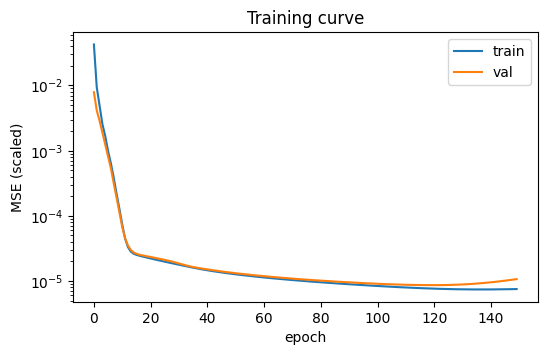

Test MAE: 0.23 (in original units, on 100 series the model never saw)


In [5]:
es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)
hist = model.fit(X_train, y_train, epochs=600, batch_size=32,
                 validation_data=(X_val, y_val), callbacks=[es], verbose=0)   # validation set, NOT the test set
print(f"Stopped after {len(hist.history['loss'])} epochs")

plt.figure(figsize=(6,3.5))
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (scaled)"); plt.legend(); plt.title("Training curve"); plt.show()

test_mae = model.evaluate(X_test, y_test, verbose=0)[1] * SCALE
print(f"Test MAE: {test_mae:.2f} (in original units, on 100 series the model never saw)")

[17 22 27 32 37] -> true 42, predicted 41.8
[ 5  7  9 11 13] -> true 15, predicted 15.0
[15 17 19 21 23] -> true 25, predicted 24.6
[ 4 10 16 22 28] -> true 34, predicted 34.1
[23 30 37 44 51] -> true 58, predicted 57.8
[33 34 35 36 37] -> true 38, predicted 37.6
[15 18 21 24 27] -> true 30, predicted 29.7
[16 23 30 37 44] -> true 51, predicted 50.9


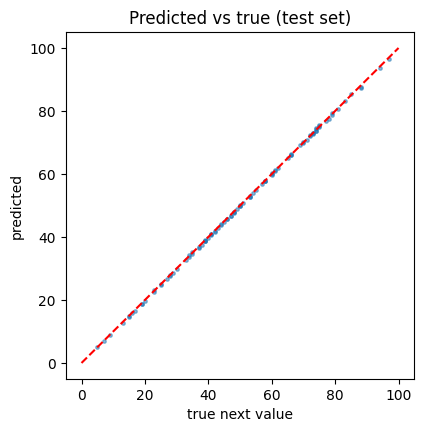

In [6]:
pred = model.predict(X_test, verbose=0).ravel() * SCALE
true = y_test * SCALE
for i in range(8):
    print(f"{np.round(X_test[i,:,0]*SCALE).astype(int)} -> true {true[i]:.0f}, predicted {pred[i]:.1f}")

plt.figure(figsize=(4.5,4.5))
plt.scatter(true, pred, s=6, alpha=.5); plt.plot([0,100],[0,100],"r--")
plt.xlabel("true next value"); plt.ylabel("predicted"); plt.title("Predicted vs true (test set)"); plt.show()

## 5. Check the equations against the trained weights
We recompute the RNN **by hand with NumPy** using equations 1–3 and the trained weights. It must match Keras exactly.

In [7]:
Wxh, Whh, bh = model.layers[0].get_weights()     # (1,8), (8,8), (8,)
Why, by      = model.layers[1].get_weights()     # (8,1), (1,)

def rnn_forward(seq):                            # seq: 5 raw numbers
    h = np.zeros(Wxh.shape[1])                   # h0 = 0
    for x_t in np.array(seq, dtype="float32") / SCALE:
        h = np.tanh(x_t * Wxh[0] + h @ Whh + bh) # eq 1 + 2
    return float(h @ Why[:, 0] + by[0]) * SCALE  # eq 3

s = [10, 20, 30, 40, 50]
keras_out = model.predict(np.array(s, dtype="float32").reshape(1, 5, 1) / SCALE, verbose=0)[0, 0] * SCALE
print("NumPy by hand:", round(rnn_forward(s), 4), "| Keras:", round(float(keras_out), 4))
print("Shapes  Wxh", Wxh.shape, " Whh", Whh.shape, " bh", bh.shape, " Why", Why.shape, " by", by.shape)

NumPy by hand: 59.9656 | Keras: 59.9656
Shapes  Wxh (1, 8)  Whh (8, 8)  bh (8,)  Why (8, 1)  by (1,)


### 5b. The hidden state changes at every step; the weights do not
Same `Wxh, Whh, bh` at every step, but a different $h_t$ each time. Five different vectors appear below.

In [8]:
h = np.zeros(Wxh.shape[1])
for t, x_t in enumerate(np.array([10, 20, 30, 40, 50]) / SCALE, 1):
    h = np.tanh(x_t * Wxh[0] + h @ Whh + bh)
    print(f"h_{t} =", np.round(h, 2))
print("\nW_hh = 64 separate learned numbers. Keras computes h @ W_hh, so row j, column i = weight FROM unit j TO unit i:")
print(np.round(Whh, 2))
print("Largest singular value of W_hh:", round(float(np.linalg.norm(Whh, 2)), 3))

h_1 = [ 0.08  0.03  0.02  0.19 -0.01 -0.03 -0.03  0.01]
h_2 = [ 0.1   0.13  0.01  0.27  0.01  0.06  0.01 -0.02]
h_3 = [0.17 0.23 0.05 0.33 0.   0.04 0.04 0.07]
h_4 = [ 0.25  0.27  0.06  0.34 -0.02  0.02  0.13  0.04]
h_5 = [ 0.35  0.3   0.18  0.36 -0.02  0.01  0.12  0.06]

W_hh = 64 separate learned numbers. Keras computes h @ W_hh, so row j, column i = weight FROM unit j TO unit i:
[[ 0.06 -0.16  0.45  0.3  -0.52  0.46  0.01 -0.34]
 [ 0.44  0.23 -0.41 -0.29 -0.54  0.07  0.08  0.33]
 [-0.18 -0.26  0.02 -0.34  0.39  0.64  0.32  0.24]
 [-0.46  0.64 -0.31  0.04 -0.02  0.41 -0.08 -0.07]
 [-0.37 -0.33 -0.09  0.04 -0.35 -0.31  0.4   0.4 ]
 [-0.2   0.25  0.21  0.31  0.02 -0.02  0.19  0.31]
 [-0.14  0.29  0.56 -0.53 -0.05 -0.32 -0.22  0.13]
 [-0.11  0.05 -0.24 -0.22 -0.14 -0.4   0.56 -0.65]]
Largest singular value of W_hh: 1.156


### 5c. Measure vanishing gradients on the trained model
Product of the per-step factors $\mathrm{diag}(1-h_k^2)\,W_{hh}^{\top}$ from equation 6. Its size shows how much a past input can still influence the last state. Smaller means that older inputs are harder to learn from.

influence of input 1 step(s) back: 1.1474
influence of input 2 step(s) back: 1.1472
influence of input 3 step(s) back: 1.1036
influence of input 4 step(s) back: 1.0928


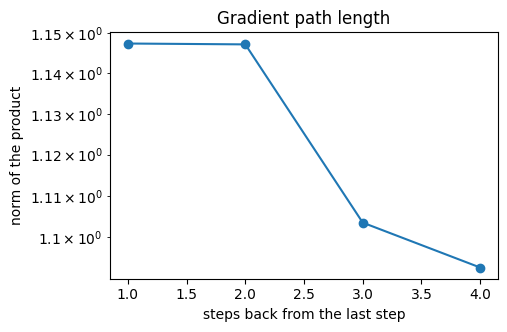

In [9]:
def hidden_states(seq):
    h = np.zeros(Wxh.shape[1]); hs = []
    for x_t in np.array(seq, dtype="float32") / SCALE:
        h = np.tanh(x_t * Wxh[0] + h @ Whh + bh); hs.append(h)
    return hs

hs = hidden_states([10, 20, 30, 40, 50])
J = [np.diag(1 - h**2) @ Whh.T for h in hs]          # dh_k / dh_(k-1) for k = 1..5
sizes, prod = [], np.eye(Whh.shape[0])
for lag in range(1, 5):                              # how far back from the last step
    prod = prod @ J[-lag]
    sizes.append(np.linalg.norm(prod, 2))
for lag, v in enumerate(sizes, 1):
    print(f"influence of input {lag} step(s) back: {v:.4f}")
plt.figure(figsize=(5,3.2)); plt.plot(range(1,5), sizes, "o-"); plt.yscale("log")
plt.xlabel("steps back from the last step"); plt.ylabel("norm of the product"); plt.title("Gradient path length"); plt.show()

**How to read this.** For this trained model the factor stays near 1 (largest singular value of $W_{hh}$ is about 1.2, and tanh slopes are near 1 because $h$ is small), so over only 4 steps the gradient neither vanishes nor explodes. Vanishing needs **long** sequences: the product has $T-t$ factors, so a factor of 0.9 per step gives $0.9^{50}\approx0.005$. Try `SEQ_LEN = 50` (trial 4) and recompute, or see how a factor above 1 explodes. This is why short windows work with a plain RNN but long ones need LSTM/GRU.

## 6. Predict on your own series
Edit `my_series` (exactly 5 numbers) and run. Try values inside **and outside** the training range and watch what happens.

In [10]:
def predict_next(seq):
    seq = list(seq); assert len(seq) == SEQ_LEN, f"give exactly {SEQ_LEN} numbers"
    x = np.array(seq, dtype="float32").reshape(1, SEQ_LEN, 1) / SCALE
    return float(model.predict(x, verbose=0)[0, 0] * SCALE)

my_series = [5, 12, 19, 26, 33]          # <-- change me (step 7 -> expect 40)
print(my_series, "-> predicted next:", round(predict_next(my_series), 2))

print("\nSanity table")
for s in ([10,20,30,40,50], [2,4,6,8,10], [7,7,7,7,7], [50,45,40,35,30], [100,200,300,400,500], [3,9,15,21,27]):
    exp = s[-1] + (s[1]-s[0])
    print(f"{str(s):28s} expected {exp:4d}   predicted {predict_next(s):8.2f}")

[5, 12, 19, 26, 33] -> predicted next: 40.12

Sanity table


[10, 20, 30, 40, 50]         expected   60   predicted    59.97
[2, 4, 6, 8, 10]             expected   12   predicted    12.08
[7, 7, 7, 7, 7]              expected    7   predicted     6.82


[50, 45, 40, 35, 30]         expected   25   predicted    24.72
[100, 200, 300, 400, 500]    expected  600   predicted   264.65


[3, 9, 15, 21, 27]           expected   33   predicted    33.15


**Read the table.** In-range series are accurate. The decreasing series `[50,45,…]` has a step (−5) never seen in training, yet it is only slightly off, because the learned rule is close to linear and interpolates. `[100,200,…,500]` is far outside the training range (max value 100): the model **cannot extrapolate** (`tanh` saturates, so the output is bounded) and predicts far less than 600 (under 300 when we ran it). *A neural network only learns the region of data it has seen.*

### Multi-step forecast
Feed each prediction back as input (**recursive forecasting**). Errors accumulate at every step.

predicted: [29.1, 34.1, 38.9, 43.6, 48.3, 52.9]
true     : [29, 34, 39, 44, 49, 54]


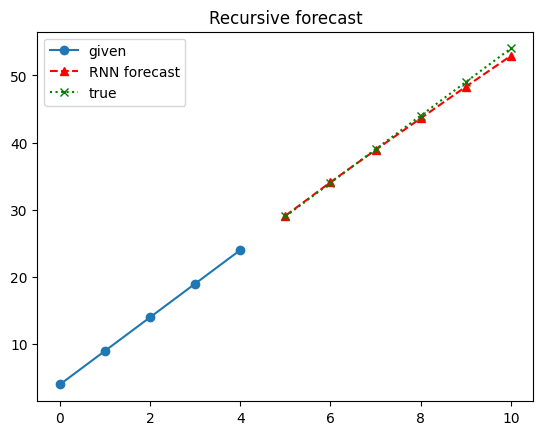

In [11]:
def forecast(seq, steps=5):
    seq = list(seq); out = []
    for _ in range(steps):
        nxt = predict_next(seq[-SEQ_LEN:]); out.append(round(nxt, 1)); seq.append(nxt)
    return out

start = [4, 9, 14, 19, 24]
f = forecast(start, 6)
true_f = [29, 34, 39, 44, 49, 54]
print("predicted:", f); print("true     :", true_f)
plt.plot(range(5), start, "o-", label="given"); plt.plot(range(5, 11), f, "r^--", label="RNN forecast")
plt.plot(range(5, 11), true_f, "gx:", label="true"); plt.legend(); plt.title("Recursive forecast"); plt.show()

## 7. Trials — change one thing at a time and record what happens

| # | Trial | What to change | What to observe / expected insight |
|---|---|---|---|
| 1 | **Units** | `SimpleRNN(2)`, `(4)`, `(16)`, `(64)` | Test MAE vs parameter count. Is bigger always better for a task this simple? |
| 2 | **No scaling** | Set `SCALE = 1.0` | Training becomes slow/unstable: `tanh` saturates on large inputs. |
| 3 | **Activation** | `SimpleRNN(8, activation="relu")` | Faster fit? Any exploding loss / `nan`? |
| 4 | **Sequence length** | `SEQ_LEN = 3`, `8`, `20` (re-run Section 3) | Does a longer window help or hurt a simple arithmetic series? |
| 5 | **Wider range** | start in `[0,500]`, step in `[1,50]`, `SCALE = 1000` | Does error grow in absolute terms? Does it extrapolate better? |
| 6 | **Negative steps** | step in `[-10,10]` | Needs the model to learn both directions. |
| 7 | **Harder pattern** | squares `1,4,9,16,25 → 36`, or Fibonacci `1,1,2,3,5 → 8` | Non-linear rules need more units or an LSTM. |
| 8 | **Stack layers** | `SimpleRNN(8, return_sequences=True)` then `SimpleRNN(8)` | Why is `return_sequences=True` needed on the first one? |
| 9 | **LSTM / GRU** | Replace `SimpleRNN` with `LSTM(8)` / `GRU(8)` | Compare MAE, parameter count (LSTM = 4×, GRU = 3× a SimpleRNN) and epochs to converge. |
| 10 | **Noise** | Add `rng.normal(0, 1, ...)` to the series | Robustness. Does the RNN average out noise? |
| 11 | **Dataset size** | train on `train_i[:40]` instead of all of `train_i` | Over-fitting: watch the gap between train and val loss. |
| 12 | **Exploding gradients** | `Adam(0.5)` then add `clipnorm=1.0` | See divergence, then the effect of gradient clipping. |
| 13 | **Break the memory** | Shuffle the 5 input numbers before predicting | Proves the model uses *order*, not just the values. |
| 14 | **Two features per step** ($d=2$) | Feed `[value, step_index]` per step: `X` shape `(N,5,2)`, `Input(shape=(SEQ_LEN,2))` | RNN layer grows from 80 to $8(2+8+1)=88$ parameters. Confirm with `model.count_params()`. |

### Exercises
1. From the trained weights, what is the **largest absolute value** in $W_{hh}$? What does it say about how much past state is kept?
2. Compute the parameter count by hand for `SimpleRNN(16)` + `Dense(1)` and confirm with `model.summary()`.
3. From `Whh`, which unit relies most on unit 1's previous value? (Look at **row 0**: Keras computes `h @ Whh`, so rows are "from" and columns are "to", the transpose of the $w_{ij}$ table in section 2.6.)
4. Why does the model fail on `[100,200,300,400,500]` while a plain formula $x_5 + (x_2-x_1)$ would not? What is the model actually learning?

### Cheat sheet
```
Input shape      : (batch, timesteps, features)
h_t              : tanh(Wxh·x_t + Whh·h_{t-1} + b)
Output           : Why·h_T + b   (linear for regression)
Params           : n(d+n+1) + (n+1)
Problem          : vanishing / exploding gradients  ->  LSTM, GRU, clipping
Always           : scale inputs, check shapes, start tiny, then grow
```